# Blends em instâncias reduzidas: silos, misturadora obrigatória e porto seco

**Disciplina:** GCC118 Programação Matemática, Fases 2 e 3 (modelo PLI, solver e heurística).
**Modelo:** `03_modelo_PLI_blends.md` · **Código:** `cafe_blend.py` (PLI, avaliador, força bruta) e `cafe_blend_heur.py` (construção + VND + ILS).

Cada rota produz **um lote de blend** (19,2 t, 1 contêiner):

`garagem → silos dos tipos do blend → misturadora → porto seco → garagem`

O modelo decide **quais silos** visitar, **quanto** retirar de cada um (respeitando as proporções do blend e os estoques), **em que ordem**, **qual misturadora** e **qual porto seco**.

### O que mudou em relação ao notebook do Nível 1

| Item | Nível 1 (`nivel1_cvrp_portos_secos.ipynb`) | Este notebook |
|---|---|---|
| Rede | pontos sintéticos num plano, desvio viário 1,25 | **municípios reais** do Sul de Minas, distâncias e tempos **OSRM** (Fase 1) |
| Terminais | 2 portos secos sintéticos | **5 recintos alfandegados de MG** (Receita Federal e Colfac-MG) |
| Diesel | R\$ 6,20/L (exemplo) | **P50 da ANP-MG** nas últimas 104 semanas |
| Pontos visitados | todas as coletas | só os **silos escolhidos** (cada silo guarda um tipo de café) |
| Produto | 1 produto | **blend**: proporção fixa de cada tipo |
| Etapa intermediária | nenhuma | **misturadora obrigatória** antes do porto seco |

> **Aviso.** As instâncias são **SEMI-REAIS**. A rede, as distâncias, os tempos, os recintos e o diesel são reais (dados da Fase 1). Quais municípios têm silo de cada tipo, os estoques, as tarifas dos silos, as misturadoras, os custos dos terminais e as janelas são **sintéticos**, com semente fixa, apenas para representar o problema.

## 1. Dependências e funções auxiliares

In [1]:
import importlib
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import cafe_blend, cafe_blend_heur
importlib.reload(cafe_blend); importlib.reload(cafe_blend_heur)
from cafe_blend import make_semireal_instance, solve_blend, evaluate, brute_force, describe, need_of
from cafe_blend_heur import ils
pd.set_option('display.width', 160)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'axes.axisbelow': True, 'font.size': 9})
CORES_ROTA = ['#2a78d6', '#eb6834']
MARCA_TIPO = ['o', 's', 'D']

def tabela_silos(inst):
    return pd.DataFrame([dict(silo=inst['nomes'][s], tipo=inst['rotulo_tipo'][inst['tipo'][s]], estoque_t=inst['e'][s],
                              tarifa_R_por_t=inst['p'][s], janela_h=f"{inst['janela'][s][0]:.1f}–{inst['janela'][s][1]:.1f}")
                         for s in inst['S']])

def tabela_custos(inst, sol):
    ev = evaluate(inst, sol)
    linha = {k: round(v, 2) for k, v in ev['components'].items()}
    linha['total'] = round(ev['cost'], 2); linha['viável'] = ev['feasible']
    return pd.DataFrame([linha])

def tabela_horarios(inst, sol, b=0):
    ev = evaluate(inst, sol); T = ev['lots'][b]['T']
    return pd.DataFrame([dict(nó=inst['nomes'][i], início_serviço_h=round(t, 2), janela_h=f"{inst['janela'][i][0]:.1f}–{inst['janela'][i][1]:.1f}",
                              serviço_h=inst['serv'][i]) for i, t in T.items() if i != inst['G']])

def mostrar(inst, res, titulo):
    print(f"{titulo}: {res['status']} | custo R$ {res['obj']:.2f} | {res['time']:.2f} s | "
          f"binárias {res['n_bin']} | variáveis {res['n_vars']} | restrições {res['n_cons']}")
    print(*describe(inst, res['sol']), sep='\n')

def mapa(inst, sol=None, titulo=''):
    """Dois painéis: recorte da região dos silos (esquerda) e visão geral com os 5 recintos (direita)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={'width_ratios': [1.25, 1]})
    _desenha(inst, sol, ax1, rotulos=True)
    _desenha(inst, sol, ax2, rotulos=False)
    xy = inst['coords']
    nos = [inst['G']] + inst['S'] + inst['M']
    xs, ys = [xy[n][0] for n in nos], [xy[n][1] for n in nos]
    ax1.set_xlim(min(xs) - 0.12, max(xs) + 0.12); ax1.set_ylim(min(ys) - 0.1, max(ys) + 0.1)
    ax1.set_title(titulo + ' (recorte da região dos silos)')
    ax2.set_title('visão geral: recintos alfandegados de MG', pad=14)
    for d in inst['D']:
        if xy[d] == xy[inst['G']]:
            continue   # CLIA Varginha coincide com a garagem; rotulado no recorte
        ax2.annotate(inst['nomes'][d].split('(')[0].replace('Porto Seco ', 'P.S. ').strip(), xy[d],
                     textcoords='offset points', xytext=(-10, 7), fontsize=7)
    alcas, nomes = ax1.get_legend_handles_labels()
    fig.legend(alcas, nomes, loc='lower center', ncol=5, fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0.1, 1, 1))

def _desenha(inst, sol, ax, rotulos):
    xy = inst['coords']
    if sol:
        for b, ls in enumerate(sol['lots']):
            r = ls['route']
            ax.plot([xy[n][0] for n in r], [xy[n][1] for n in r], '-', color=CORES_ROTA[b % 2], lw=2, zorder=2,
                    label=f'rota do lote {b}')
    for k in inst['tipos']:
        Sk = [s for s in inst['S'] if inst['tipo'][s] == k]
        ax.scatter([xy[s][0] for s in Sk], [xy[s][1] for s in Sk], marker=MARCA_TIPO[k], s=60, color='white',
                   edgecolor='#52514e', lw=1.2, zorder=4, label=f"silo {inst['rotulo_tipo'][k]}")
    ax.scatter(*xy[inst['G']], marker='s', s=110, color='#0b0b0b', zorder=5, label='garagem (Varginha)')
    ax.scatter([xy[m][0] for m in inst['M']], [xy[m][1] for m in inst['M']], marker='h', s=170, color='#6250d6',
               zorder=5, label='misturadora')
    ax.scatter([xy[d][0] for d in inst['D']], [xy[d][1] for d in inst['D']], marker='^', s=140, color='#e34948',
               zorder=5, label='porto seco / CLIA')
    if rotulos:
        for n in [inst['G']] + inst['S'] + inst['M']:
            ax.annotate(inst['nomes'][n] if n != inst['G'] else 'Varginha (garagem e CLIA)', xy[n],
                        textcoords='offset points', xytext=(6, 6), fontsize=8, color='#0b0b0b')
    ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_aspect('equal')

## 2. Rede reduzida e blend de referência

- **Garagem:** Varginha.
- **Silos (sintéticos, em municípios produtores reais):** dois por tipo, todos a até cerca de 1 h de Varginha.
- **Misturadoras candidatas:** Três Pontas e Alfenas.
- **Portos secos:** os cinco recintos alfandegados de MG.
- **Blend de referência:** 10% tipo 2, 25% tipo 4 e 65% tipo 8. Com 19,2 t, isso dá 1,92 t, 4,80 t e 12,48 t.

SEMI-REAL (rede real, blends sinteticos) | diesel S10 (P50 ANP-MG) = R$ 6.01/L | Q = 30.0 t | Tmax = 16.0 h
Demanda por tipo (t): {'tipo 2': 1.92, 'tipo 4': 4.8, 'tipo 8': 12.48}


,Porto Seco de Juiz de Fora,Porto Seco do Triângulo,CLIA Varginha,CLIA Pouso Alegre,CLIA Betim
Varginha,308.0,442.0,0.0,124.0,283.0
Elói Mendes,311.0,424.0,19.0,121.0,298.0
Machado,348.0,409.0,70.0,75.0,349.0
Carmo da Cachoeira,295.0,440.0,36.0,137.0,229.0
Paraguaçu,344.0,404.0,40.0,101.0,319.0
Campos Gerais,338.0,369.0,75.0,145.0,273.0
Três Corações,280.0,473.0,33.0,113.0,263.0
Três Pontas,336.0,405.0,29.0,152.0,257.0
Alfenas,373.0,379.0,69.0,109.0,308.0


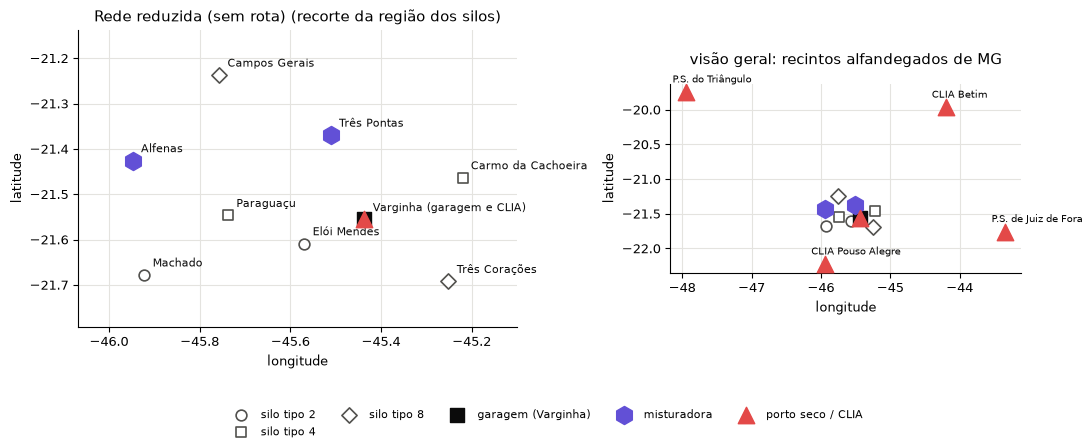

In [2]:
SILOS = {'tipo 2': ['Elói Mendes', 'Machado'],
         'tipo 4': ['Carmo da Cachoeira', 'Paraguaçu'],
         'tipo 8': ['Campos Gerais', 'Três Corações']}
UM_POR_TIPO = [v[0] for v in SILOS.values()]
DOIS_POR_TIPO = [s for v in SILOS.values() for s in v]
BLEND_REF = {0: 0.10, 1: 0.25, 2: 0.65}
SEMENTE = 4

base = make_semireal_instance(n_types=3, silos_per_type=2, silos=DOIS_POR_TIPO, mixers=('Três Pontas', 'Alfenas'), seed=SEMENTE)
print(base['sintetica'], f"| diesel S10 (P50 ANP-MG) = R$ {base['diesel']:.2f}/L | Q = {base['Q']} t | Tmax = {base['Tmax']} h")
print('Demanda por tipo (t):', {base['rotulo_tipo'][k]: round(v, 2) for k, v in need_of(base, base['lots'][0]).items()})
dist = pd.DataFrame(base['dist'], index=base['nomes'], columns=base['nomes']).round(0)
display(dist.loc[['Varginha'] + [base['nomes'][s] for s in base['S']] + [base['nomes'][m] for m in base['M']],
                 [base['nomes'][d] for d in base['D']]].rename(columns=lambda n: n.split('(')[0].strip()))
mapa(base, titulo='Rede reduzida (sem rota)'); plt.show()

A tabela acima mostra a distância rodoviária (km, OSRM) de cada nó até cada recinto. O CLIA de Varginha fica dentro da região, enquanto Juiz de Fora, Uberaba e Betim estão a mais de 200 km. Por isso o porto seco só muda quando o custo de entrada favorece um terminal distante.

## 3. R1 — nível B1 (mínimo): 1 silo por tipo, 1 misturadora

Com um silo por tipo, as retiradas ficam fixas (1,92 / 4,80 / 12,48 t). O modelo decide só a **ordem dos silos** e o **porto seco**. A força bruta enumera todas as ordens × portos e confirma o ótimo do PLI.

,silo,tipo,estoque_t,tarifa_R_por_t,janela_h
0,Elói Mendes,tipo 2,2.9,37.9,0.0–16.0
1,Carmo da Cachoeira,tipo 4,8.8,34.1,0.0–16.0
2,Campos Gerais,tipo 8,17.2,28.4,0.0–16.0


R1: Optimal | custo R$ 2402.14 | 0.16 s | binárias 26 | variáveis 41 | restrições 58
lote 0: Varginha -> Elói Mendes[tipo 2: 1.92 t] -> Carmo da Cachoeira[tipo 4: 4.80 t] -> Campos Gerais[tipo 8: 12.48 t] -> Três Pontas -> CLIA Varginha -> Varginha
Força bruta: R$ 2402.14 (diferença para o PLI: 0.0e+00)


,veiculo,deslocamento,aquisicao,misturadora,porto,atraso,total,viável
0,350.0,1181.26,590.88,180.0,100.0,0.0,2402.14,True


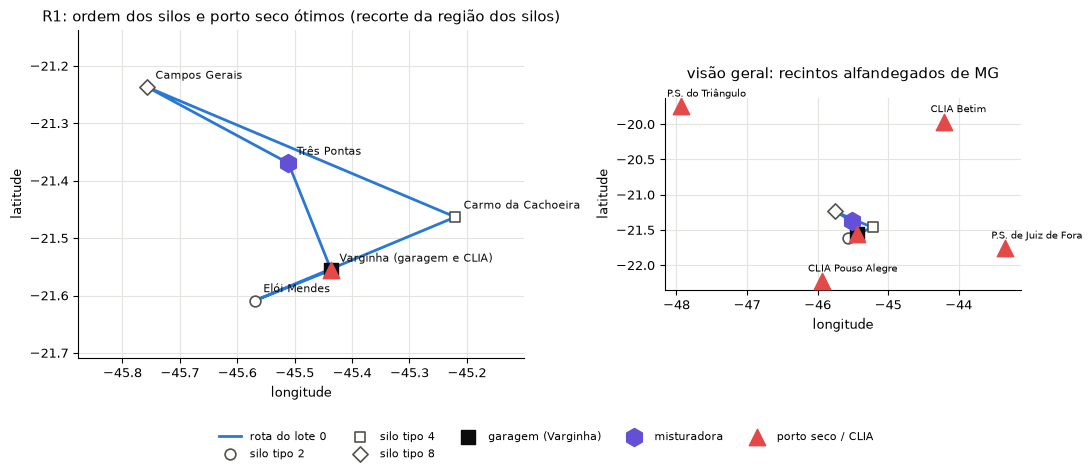

In [3]:
R1 = make_semireal_instance(n_types=3, silos_per_type=1, silos=UM_POR_TIPO, mixers=('Três Pontas',), seed=SEMENTE)
display(tabela_silos(R1))
res1 = solve_blend(R1, time_limit=60)
mostrar(R1, res1, 'R1')
bf, _ = brute_force(R1)
print(f'Força bruta: R$ {bf:.2f} (diferença para o PLI: {abs(bf - res1["obj"]):.1e})')
display(tabela_custos(R1, res1['sol']))
mapa(R1, res1['sol'], 'R1: ordem dos silos e porto seco ótimos'); plt.show()

**E se o porto seco fosse outro?** Fixando cada recinto (retirando os demais do conjunto \(D\)), vê-se quanto custa entregar fora do recinto ótimo.

In [4]:
linhas = []
for d in R1['D']:
    r = solve_blend(dict(R1, D=[d]), time_limit=60)
    ok = 'obj' in r
    linhas.append(dict(porto_seco=R1['nomes'][d], custo_entrada_R=R1['F_port'][d],
                       ida_e_volta_h=round(R1['t_arc'][R1['M'][0]][d] + R1['t_arc'][d][R1['G']], 1),
                       custo_total_R=round(r['obj'], 2) if ok else None,
                       acréscimo_R=round(r['obj'] - res1['obj'], 2) if ok else None,
                       situação='viável' if ok else f"inviável: rota passa de Tmax = {R1['Tmax']} h"))
display(pd.DataFrame(linhas).sort_values('custo_total_R', na_position='last'))

,porto_seco,custo_entrada_R,ida_e_volta_h,custo_total_R,acréscimo_R,situação
2,CLIA Varginha,100.0,0.5,2402.14,0.00,viável
3,CLIA Pouso Alegre,75.0,3.9,3655.03,1252.89,viável
4,CLIA Betim (TORA),67.0,7.8,5023.02,2620.88,viável
0,Porto Seco de Juiz de Fora (Multiterminais),84.0,10.5,NaN,NaN,inviável: rota passa de Tmax = 16.0 h
1,Porto Seco do Triângulo (EADI Uberaba),70.0,12.2,NaN,NaN,inviável: rota passa de Tmax = 16.0 h


Os recintos distantes não cabem na jornada máxima: só a ida e volta a partir da misturadora já consome boa parte de \(T_{max}\), somada à coleta e à mistura. Numa instância real, isso pediria pernoite ou troca de motorista, o que fica fora do escopo deste nível.

## 4. R2 — nível B2: 2 silos por tipo (escolha de silos e quantidades)

Cada tipo está em dois silos, com estoque e tarifa diferentes. Às vezes um silo sozinho não tem estoque para o tipo inteiro, e aí a carga é dividida entre dois. É o *Traveling Purchaser Problem*: o modelo troca deslocamento por tarifa e estoque.

,silo,tipo,estoque_t,tarifa_R_por_t,janela_h
0,Elói Mendes,tipo 2,1.9,35.0,0.0–16.0
1,Machado,tipo 2,2.9,34.1,0.0–16.0
2,Carmo da Cachoeira,tipo 4,3.9,21.9,0.0–16.0
3,Paraguaçu,tipo 4,5.5,19.3,0.0–16.0
4,Campos Gerais,tipo 8,8.8,38.2,0.0–16.0
5,Três Corações,tipo 8,10.2,35.7,0.0–16.0


R2: Optimal | custo R$ 2686.48 | 0.22 s | binárias 59 | variáveis 83 | restrições 124
lote 0: Varginha -> Três Corações[tipo 8: 10.20 t] -> Paraguaçu[tipo 4: 4.80 t] -> Machado[tipo 2: 1.92 t] -> Campos Gerais[tipo 8: 2.28 t] -> Três Pontas -> CLIA Varginha -> Varginha


,veiculo,deslocamento,aquisicao,misturadora,porto,atraso,total,viável
0,350.0,1447.13,609.35,180.0,100.0,0.0,2686.48,True


,silo,tipo,estoque_t,retirado_t,visitado
0,Elói Mendes,tipo 2,1.9,0.00,False
1,Machado,tipo 2,2.9,1.92,True
2,Carmo da Cachoeira,tipo 4,3.9,0.00,False
3,Paraguaçu,tipo 4,5.5,4.80,True
4,Campos Gerais,tipo 8,8.8,2.28,True
5,Três Corações,tipo 8,10.2,10.20,True


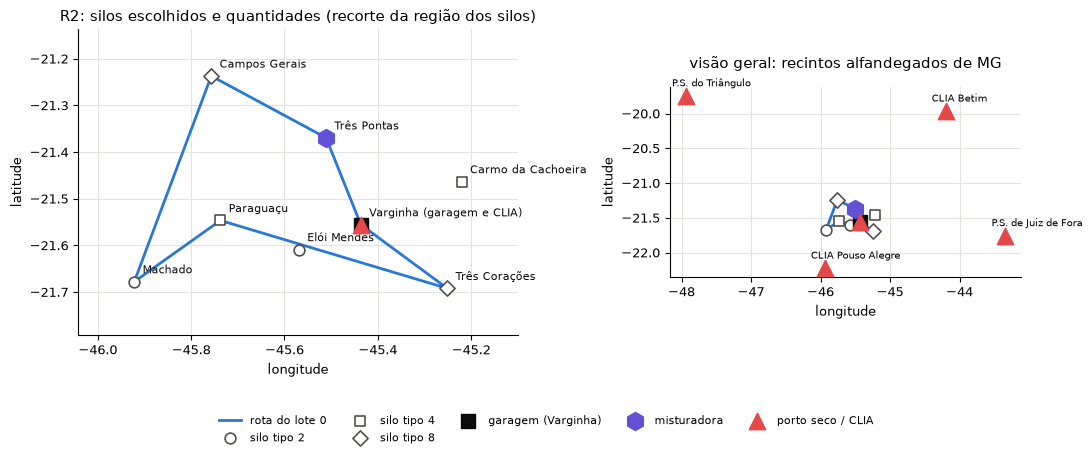

In [5]:
R2 = make_semireal_instance(n_types=3, silos_per_type=2, silos=DOIS_POR_TIPO, mixers=('Três Pontas',), seed=SEMENTE)
display(tabela_silos(R2))
res2 = solve_blend(R2, time_limit=60)
mostrar(R2, res2, 'R2')
display(tabela_custos(R2, res2['sol']))
ret = res2['sol']['lots'][0]['r']
display(pd.DataFrame([dict(silo=R2['nomes'][s], tipo=R2['rotulo_tipo'][R2['tipo'][s]], estoque_t=R2['e'][s],
                           retirado_t=round(ret.get(s, 0.0), 2), visitado=s in ret) for s in R2['S']]))
mapa(R2, res2['sol'], 'R2: silos escolhidos e quantidades'); plt.show()

## 5. R3 — nível B3: escolha da misturadora

Duas misturadoras candidatas: Três Pontas e Alfenas. A tabela compara a escolha livre com cada misturadora fixada.

In [6]:
R3 = make_semireal_instance(n_types=3, silos_per_type=2, silos=DOIS_POR_TIPO, mixers=('Três Pontas', 'Alfenas'), seed=SEMENTE)
res3 = solve_blend(R3, time_limit=60)
mostrar(R3, res3, 'R3')
linhas = [dict(caso='livre (ótimo)', misturadora=R3['nomes'][res3['sol']['lots'][0]['route'][-3]],
               porto=R3['nomes'][res3['sol']['lots'][0]['route'][-2]], custo_R=round(res3['obj'], 2))]
for m in R3['M']:
    r = solve_blend(dict(R3, M=[m]), time_limit=60)
    linhas.append(dict(caso=f"fixa: {R3['nomes'][m]} (F = R$ {R3['F_mix'][m]:.0f}, {R3['serv'][m]} h)",
                       misturadora=R3['nomes'][m], porto=R3['nomes'][r['sol']['lots'][0]['route'][-2]], custo_R=round(r['obj'], 2)))
display(pd.DataFrame(linhas))

R3: Optimal | custo R$ 2686.48 | 0.23 s | binárias 71 | variáveis 96 | restrições 138
lote 0: Varginha -> Três Corações[tipo 8: 10.20 t] -> Paraguaçu[tipo 4: 4.80 t] -> Machado[tipo 2: 1.92 t] -> Campos Gerais[tipo 8: 2.28 t] -> Três Pontas -> CLIA Varginha -> Varginha


,caso,misturadora,porto,custo_R
0,livre (ótimo),Três Pontas,CLIA Varginha,2686.48
1,"fixa: Três Pontas (F = R$ 180, 1.5 h)",Três Pontas,CLIA Varginha,2686.48
2,"fixa: Alfenas (F = R$ 150, 1.5 h)",Alfenas,CLIA Varginha,2841.74


## 6. R4 — nível B4: janelas de tempo

- **Silos:** janela dura (horário de expedição do armazém).
- **Misturadora:** atende entre 1 h e 11 h.
- **Porto seco:** *cut-off* flexível, com penalidade \(\beta\) = R\$ 200 por hora de atraso.

Os horários são contados a partir da saída da garagem.

,silo,tipo,estoque_t,tarifa_R_por_t,janela_h
0,Elói Mendes,tipo 2,1.9,35.0,1.0–7.4
1,Machado,tipo 2,2.9,34.1,0.5–5.0
2,Carmo da Cachoeira,tipo 4,3.9,21.9,1.0–6.9
3,Paraguaçu,tipo 4,5.5,19.3,3.0–9.9
4,Campos Gerais,tipo 8,8.8,38.2,1.0–5.3
5,Três Corações,tipo 8,10.2,35.7,2.0–7.0


R4: Optimal | custo R$ 3557.02 | 2.11 s | binárias 71 | variáveis 97 | restrições 138
lote 0: Varginha -> Campos Gerais[tipo 8: 2.28 t] -> Machado[tipo 2: 1.92 t] -> Paraguaçu[tipo 4: 4.80 t] -> Três Corações[tipo 8: 10.20 t] -> Três Pontas -> CLIA Varginha -> Varginha


,nó,início_serviço_h,janela_h,serviço_h
0,Campos Gerais,1.30,1.0–5.3,0.5
1,Machado,3.12,0.5–5.0,0.5
2,Paraguaçu,4.18,3.0–9.9,0.5
3,Três Corações,5.80,2.0–7.0,0.5
4,Três Pontas,7.40,1.0–11.0,1.5
5,CLIA Varginha,9.41,0.0–6.7,1.0


Atraso no cut-off: 2.71 h (R$ 541.60) | fim da rota: 10.41 h | custo sem janelas (R3): R$ 2686.48


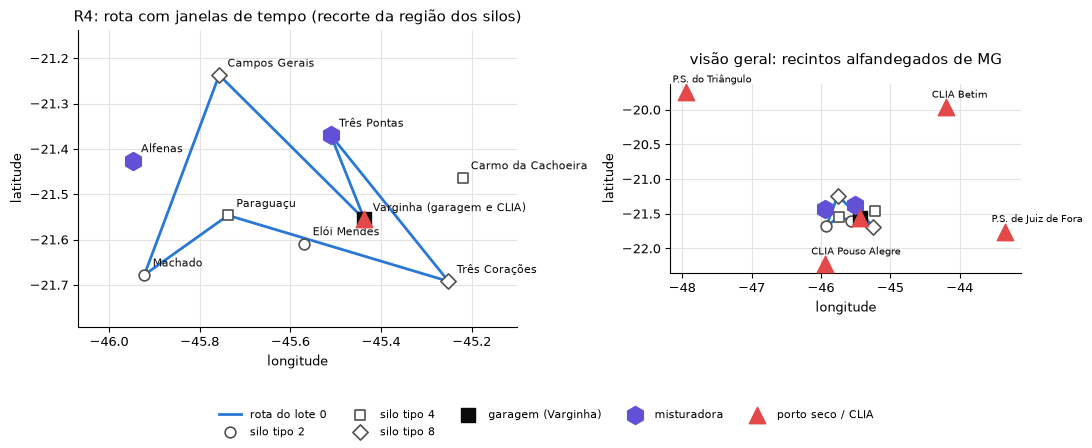

In [7]:
R4 = make_semireal_instance(n_types=3, silos_per_type=2, silos=DOIS_POR_TIPO, mixers=('Três Pontas', 'Alfenas'), tw=True, seed=SEMENTE)
display(tabela_silos(R4))
res4 = solve_blend(R4, time_limit=60)
mostrar(R4, res4, 'R4')
display(tabela_horarios(R4, res4['sol']))
ev4 = evaluate(R4, res4['sol'])
print(f"Atraso no cut-off: {ev4['lots'][0]['late']:.2f} h (R$ {ev4['components']['atraso']:.2f}) | "
      f"fim da rota: {ev4['lots'][0]['fim']:.2f} h | custo sem janelas (R3): R$ {res3['obj']:.2f}")
mapa(R4, res4['sol'], 'R4: rota com janelas de tempo'); plt.show()

Compare a ordem dos silos com a do R3: as janelas podem obrigar a visitar primeiro o silo que fecha mais cedo, mesmo que isso aumente o deslocamento. Se o caminhão ainda assim chega depois do *cut-off*, o atraso aparece como custo, e o modelo pondera esse custo contra rotas alternativas.

## 7. R5 — nível B5: dois lotes com blends diferentes e estoque compartilhado

- **Lote 0:** blend de referência (10/25/65).
- **Lote 1:** blend mais suave (30% tipo 2, 50% tipo 4, 20% tipo 8).

Cada lote tem a sua rota, mas os dois disputam os **mesmos silos**: a soma das retiradas não pode passar do estoque.

R5: Optimal | custo R$ 4523.12 | 1.35 s | binárias 142 | variáveis 194 | restrições 282
lote 0: Varginha -> Elói Mendes[tipo 2: 1.92 t] -> Três Corações[tipo 8: 12.48 t] -> Carmo da Cachoeira[tipo 4: 4.80 t] -> Três Pontas -> CLIA Varginha -> Varginha
lote 1: Varginha -> Elói Mendes[tipo 2: 5.76 t] -> Paraguaçu[tipo 4: 9.60 t] -> Campos Gerais[tipo 8: 3.84 t] -> Três Pontas -> CLIA Varginha -> Varginha


,silo,tipo,estoque_t,lote0_t,lote1_t,sobra_t
0,Elói Mendes,tipo 2,7.7,1.92,5.76,0.02
1,Machado,tipo 2,11.7,0.00,0.00,11.70
2,Carmo da Cachoeira,tipo 4,11.8,4.80,0.00,7.00
3,Paraguaçu,tipo 4,16.4,0.00,9.60,6.80
4,Campos Gerais,tipo 8,11.5,0.00,3.84,7.66
5,Três Corações,tipo 8,13.3,12.48,0.00,0.82


,veiculo,deslocamento,aquisicao,misturadora,porto,atraso,total,viável
0,700.0,1813.7,1151.42,360.0,200.0,298.0,4523.12,True


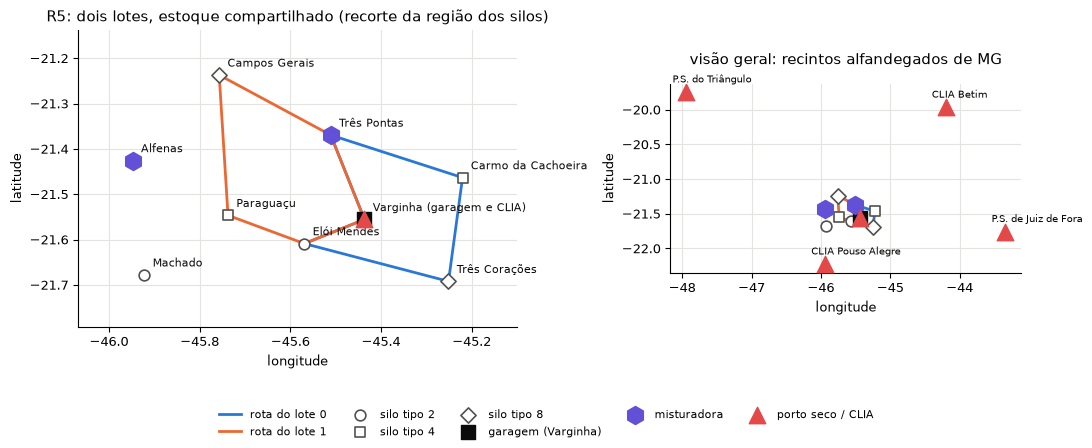

In [8]:
BLENDS = [BLEND_REF, {0: 0.30, 1: 0.50, 2: 0.20}]
R5 = make_semireal_instance(n_types=3, silos_per_type=2, silos=DOIS_POR_TIPO, mixers=('Três Pontas', 'Alfenas'),
                            tw=True, n_lots=2, blends=BLENDS, seed=SEMENTE)
res5 = solve_blend(R5, time_limit=120)
mostrar(R5, res5, 'R5')
uso = pd.DataFrame([dict(silo=R5['nomes'][s], tipo=R5['rotulo_tipo'][R5['tipo'][s]], estoque_t=R5['e'][s],
                         lote0_t=round(res5['sol']['lots'][0]['r'].get(s, 0), 2), lote1_t=round(res5['sol']['lots'][1]['r'].get(s, 0), 2))
                    for s in R5['S']])
uso['sobra_t'] = (uso['estoque_t'] - uso['lote0_t'] - uso['lote1_t']).round(2)
display(uso)
display(tabela_custos(R5, res5['sol']))
mapa(R5, res5['sol'], 'R5: dois lotes, estoque compartilhado'); plt.show()

## 8. Resumo: exato × heurística nas instâncias reduzidas

Mesmas instâncias, resolvidas pelo PLI (CBC) e pela heurística (construção + VND + ILS, até 10 s). Todas as soluções passam pelo avaliador independente.

In [9]:
linhas = []
for nome, inst, ex in [('R1 (B1)', R1, res1), ('R2 (B2)', R2, res2), ('R3 (B3)', R3, res3), ('R4 (B4)', R4, res4), ('R5 (B5)', R5, res5)]:
    h = ils(inst, iters=150, time_limit=10, seed=1)
    ev = evaluate(inst, ex['sol'])
    linhas.append(dict(instância=nome, nós=len(inst['nomes']), silos=len(inst['S']), misturadoras=len(inst['M']),
                       lotes=len(inst['lots']), binárias=ex['n_bin'], variáveis=ex['n_vars'], restrições=ex['n_cons'],
                       status=ex['status'], custo_exato=round(ex['obj'], 2), tempo_exato_s=round(ex['time'], 2),
                       exato_viável=ev['feasible'], custo_construção=round(h['construction_cost'], 2),
                       custo_ILS=round(h['cost'], 2), tempo_ILS_s=round(h['time'], 2),
                       gap_ILS_pct=round(100 * (h['cost'] / ex['obj'] - 1), 2) + 0.0, ILS_viável=h['feasible']))
resumo = pd.DataFrame(linhas); display(resumo)

,instância,nós,silos,misturadoras,lotes,binárias,variáveis,restrições,status,custo_exato,tempo_exato_s,exato_viável,custo_construção,custo_ILS,tempo_ILS_s,gap_ILS_pct,ILS_viável
0,R1 (B1),10,3,1,1,26,41,58,Optimal,2402.14,0.16,True,2402.14,2402.14,2.66,0.0,True
1,R2 (B2),13,6,1,1,59,83,124,Optimal,2686.48,0.22,True,2686.48,2686.48,7.61,0.0,True
2,R3 (B3),14,6,2,1,71,96,138,Optimal,2686.48,0.23,True,2686.48,2686.48,10.01,0.0,True
3,R4 (B4),14,6,2,1,71,97,138,Optimal,3557.02,2.11,True,3557.02,3557.02,8.91,0.0,True
4,R5 (B5),14,6,2,2,142,194,282,Optimal,4523.12,1.35,True,4523.12,4523.12,10.03,0.0,True


O exato resolve todas as instâncias reduzidas com prova de otimalidade em poucos segundos, e a heurística reproduz o ótimo. Isso valida os dois métodos antes de aumentar o tamanho.

## 9. Próximos passos

1. **Escalabilidade (próxima iteração):** aumentar silos por tipo, misturadoras e lotes sobre a rede real e registrar binárias, restrições, tempo e gap, como pede a Fase 2.
2. **Heurística × exato** nas instâncias em que o exato para no limite de tempo: gráfico qualidade × tempo da Fase 3.
3. **Incertezas (Fase 4):** cenários de diesel P10/P50/P90 e variação de estoques (bienalidade).